In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
pd.set_option('display.max_columns', 200)

In [4]:

app_train = pd.read_csv('application_train.csv')
bureau = pd.read_csv('bureau.csv')

In [5]:

print(app_train.shape)
print(app_train['TARGET'].value_counts(normalize=True))

(11631, 122)
TARGET
0    0.922793
1    0.077207
Name: proportion, dtype: float64


In [6]:
missing = app_train.isnull().sum() / len(app_train) * 100
missing = missing[missing > 0].sort_values(ascending=False)
print(missing.head(30))

COMMONAREA_AVG              69.761843
COMMONAREA_MODE             69.761843
COMMONAREA_MEDI             69.761843
NONLIVINGAPARTMENTS_MEDI    69.366349
NONLIVINGAPARTMENTS_MODE    69.366349
NONLIVINGAPARTMENTS_AVG     69.366349
FONDKAPREMONT_MODE          68.549566
LIVINGAPARTMENTS_AVG        68.377612
LIVINGAPARTMENTS_MEDI       68.377612
LIVINGAPARTMENTS_MODE       68.377612
FLOORSMIN_MODE              67.878944
FLOORSMIN_AVG               67.878944
FLOORSMIN_MEDI              67.878944
OWN_CAR_AGE                 66.494712
YEARS_BUILD_MODE            66.408735
YEARS_BUILD_MEDI            66.408735
YEARS_BUILD_AVG             66.408735
LANDAREA_AVG                58.911530
LANDAREA_MEDI               58.911530
LANDAREA_MODE               58.911530
BASEMENTAREA_MODE           58.068954
BASEMENTAREA_MEDI           58.068954
BASEMENTAREA_AVG            58.068954
EXT_SOURCE_1                56.332216
NONLIVINGAREA_MODE          54.569684
NONLIVINGAREA_AVG           54.569684
NONLIVINGARE

In [7]:
# Bucket columns by missingness severity
high_missing = missing[missing > 60].index.tolist()
moderate_missing = missing[(missing > 10) & (missing <= 60)].index.tolist()
low_missing = missing[missing <= 10].index.tolist()

In [8]:
print(f"High (>60%): {len(high_missing)} cols")
print(f"Moderate (10-60%): {len(moderate_missing)} cols")
print(f"Low (<10%): {len(low_missing)} cols")

High (>60%): 17 cols
Moderate (10-60%): 40 cols
Low (<10%): 53 cols


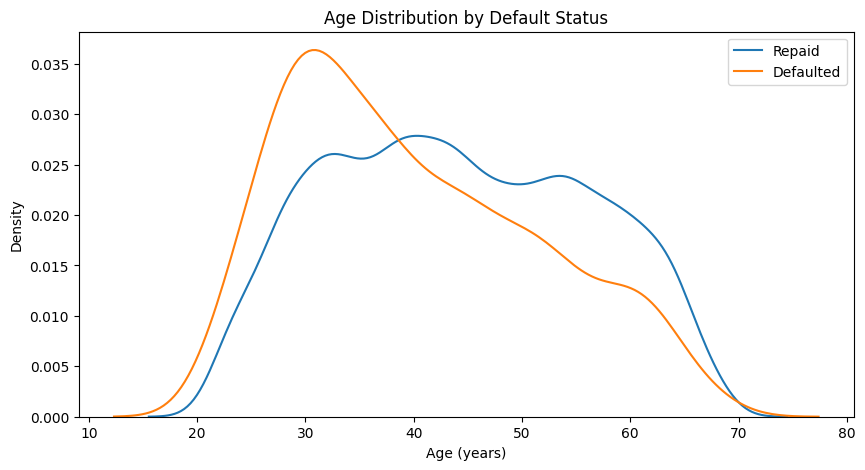

In [9]:
# Numeric feature vs target
plt.figure(figsize=(10,5))
sns.kdeplot(app_train.loc[app_train['TARGET']==0, 'DAYS_BIRTH']/-365, label='Repaid')
sns.kdeplot(app_train.loc[app_train['TARGET']==1, 'DAYS_BIRTH']/-365, label='Defaulted')
plt.xlabel('Age (years)')
plt.legend()
plt.title('Age Distribution by Default Status')
plt.show()

In [10]:
# Correlation with target (numeric only)
numeric_cols = app_train.select_dtypes(include=[np.number]).columns
correlations = app_train[numeric_cols].corr()['TARGET'].sort_values()
print("Top negative correlations (protective):\n", correlations.head(10))
print("\nTop positive correlations (risk):\n", correlations.tail(10))

Top negative correlations (protective):
 EXT_SOURCE_3      -0.196627
EXT_SOURCE_1      -0.159042
EXT_SOURCE_2      -0.158756
AMT_GOODS_PRICE   -0.049518
FLAG_PHONE        -0.043192
AMT_CREDIT        -0.041815
DAYS_EMPLOYED     -0.038817
FLOORSMIN_MEDI    -0.035866
FLOORSMIN_AVG     -0.035579
FLOORSMIN_MODE    -0.034505
Name: TARGET, dtype: float64

Top positive correlations (risk):
 REGION_RATING_CLIENT_W_CITY    0.064901
DAYS_ID_PUBLISH                0.066349
DAYS_LAST_PHONE_CHANGE         0.068626
DAYS_BIRTH                     0.092556
TARGET                         1.000000
FLAG_MOBIL                          NaN
FLAG_DOCUMENT_2                     NaN
FLAG_DOCUMENT_7                     NaN
FLAG_DOCUMENT_10                    NaN
FLAG_DOCUMENT_12                    NaN
Name: TARGET, dtype: float64


In [11]:
print(app_train['DAYS_EMPLOYED'].describe())

count     11630.000000
mean      62413.721496
std      140107.177180
min      -15632.000000
25%       -2809.500000
50%       -1222.000000
75%        -290.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64


In [12]:
app_train['DAYS_EMPLOYED_ANOMALY'] = app_train['DAYS_EMPLOYED'] == 365243
app_train['DAYS_EMPLOYED'] = app_train['DAYS_EMPLOYED'].replace(365243, np.nan)

In [13]:
# Financial burden ratios
app_train['CREDIT_INCOME_RATIO'] = app_train['AMT_CREDIT'] / app_train['AMT_INCOME_TOTAL']
app_train['ANNUITY_INCOME_RATIO'] = app_train['AMT_ANNUITY'] / app_train['AMT_INCOME_TOTAL']
app_train['CREDIT_TERM'] = app_train['AMT_ANNUITY'] / app_train['AMT_CREDIT']
app_train['DAYS_EMPLOYED_PERC'] = app_train['DAYS_EMPLOYED'] / app_train['DAYS_BIRTH']

In [14]:
bureau_agg = bureau.groupby('SK_ID_CURR').agg({
    'SK_ID_BUREAU': 'count',
    'AMT_CREDIT_SUM': ['sum', 'mean', 'max'],
    'AMT_CREDIT_SUM_DEBT': ['sum', 'mean'],
    'CREDIT_DAY_OVERDUE': ['max', 'mean'],
    'DAYS_CREDIT': ['min', 'max', 'mean'],
})
bureau_agg.columns = ['_'.join(col).strip() for col in bureau_agg.columns]
bureau_agg = bureau_agg.rename(columns={'SK_ID_BUREAU_count': 'BUREAU_LOAN_COUNT'})
bureau_agg = bureau_agg.reset_index()

app_train = app_train.merge(bureau_agg, on='SK_ID_CURR', how='left')

In [15]:
app_train['BUREAU_CREDIT_UTILIZATION'] = (
    app_train['AMT_CREDIT_SUM_DEBT_sum'] / app_train['AMT_CREDIT_SUM_sum']
)

In [16]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(app_train['TARGET'])
weights = compute_class_weight('balanced', classes=classes, y=app_train['TARGET'])
class_weight_dict = dict(zip(classes, weights))
print(class_weight_dict)

{np.int64(0): np.float64(0.5418335973166869), np.int64(1): np.float64(6.476057906458798)}


In [17]:
scale_pos_weight = (app_train['TARGET']==0).sum() / (app_train['TARGET']==1).sum()
print(f"scale_pos_weight for XGBoost: {scale_pos_weight:.2f}")  # you'll carry this into Day 2

scale_pos_weight for XGBoost: 11.95


In [18]:
#Day 2
from sklearn.model_selection import train_test_split

# Drop ID and target to form X, keep y separate
X = app_train.drop(columns=['TARGET', 'SK_ID_CURR'])
y = app_train['TARGET']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(9304, 137) (2327, 137)
0.07717110920034394 0.07735281478298238


In [19]:
cat_cols = X_train.select_dtypes(include='object').columns.tolist()
print(f"{len(cat_cols)} categorical columns")
print(X_train[cat_cols].nunique().sort_values(ascending=False).head(10))

16 categorical columns
ORGANIZATION_TYPE             58
OCCUPATION_TYPE               18
NAME_TYPE_SUITE                7
WEEKDAY_APPR_PROCESS_START     7
WALLSMATERIAL_MODE             7
NAME_INCOME_TYPE               6
NAME_EDUCATION_TYPE            6
NAME_HOUSING_TYPE              6
NAME_FAMILY_STATUS             5
FONDKAPREMONT_MODE             4
dtype: int64


In [20]:
from sklearn.preprocessing import OrdinalEncoder

# XGBoost path: ordinal/label encoding is fine — trees split on thresholds,
# they don't assume the encoded integers are linearly ordered/meaningful.
ordinal_encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
ordinal_encoder.fit(X_train[cat_cols])

X_train_xgb = X_train.copy()
X_test_xgb = X_test.copy()
X_train_xgb[cat_cols] = ordinal_encoder.transform(X_train[cat_cols])
X_test_xgb[cat_cols] = ordinal_encoder.transform(X_test[cat_cols])

In [21]:
# Logistic Regression path: one-hot encoding for low-cardinality,
# leave high-cardinality ORGANIZATION_TYPE out or frequency-encode it
from sklearn.preprocessing import OneHotEncoder

low_card_cols = [c for c in cat_cols if X_train[c].nunique() <= 10]
high_card_cols = [c for c in cat_cols if X_train[c].nunique() > 10]
print("High cardinality (handle separately):", high_card_cols)

High cardinality (handle separately): ['OCCUPATION_TYPE', 'ORGANIZATION_TYPE']


In [22]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor_lr = ColumnTransformer(transformers=[
    ('num', numeric_transformer, num_cols),
    ('cat', categorical_transformer, cat_cols)
])

In [23]:
from sklearn.linear_model import LogisticRegression

lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(
        class_weight='balanced',   # from Day 1's imbalance decision
        max_iter=1000,
        random_state=42
    ))
])

lr_pipeline.fit(X_train, y_train)
lr_probs = lr_pipeline.predict_proba(X_test)[:, 1]

In [24]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,   # 11.95, from your Day 1 calc
    eval_metric='auc',
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train_xgb, y_train,
    eval_set=[(X_test_xgb, y_test)],
    verbose=50
)

xgb_probs = xgb_model.predict_proba(X_test_xgb)[:, 1]

[0]	validation_0-auc:0.69906
[50]	validation_0-auc:0.74567
[100]	validation_0-auc:0.74479
[150]	validation_0-auc:0.73854
[200]	validation_0-auc:0.74105
[250]	validation_0-auc:0.74395
[299]	validation_0-auc:0.74039


In [25]:
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve, average_precision_score

def evaluate_model(y_true, y_probs, model_name):
    auc = roc_auc_score(y_true, y_probs)
    ap = average_precision_score(y_true, y_probs)  # PR-AUC

    fpr, tpr, thresholds = roc_curve(y_true, y_probs)
    ks_stat = np.max(tpr - fpr)
    ks_threshold = thresholds[np.argmax(tpr - fpr)]

    print(f"--- {model_name} ---")
    print(f"AUC-ROC:  {auc:.4f}")
    print(f"PR-AUC:   {ap:.4f}")
    print(f"KS Stat:  {ks_stat:.4f} at threshold {ks_threshold:.4f}")
    return auc, ap, ks_stat

evaluate_model(y_test, lr_probs, "Logistic Regression")
evaluate_model(y_test, xgb_probs, "XGBoost")

--- Logistic Regression ---
AUC-ROC:  0.7041
PR-AUC:   0.1885
KS Stat:  0.3151 at threshold 0.5440
--- XGBoost ---
AUC-ROC:  0.7404
PR-AUC:   0.2467
KS Stat:  0.3661 at threshold 0.4037


(np.float64(0.7403948662216012),
 np.float64(0.24670814640418873),
 np.float64(0.366084458934948))

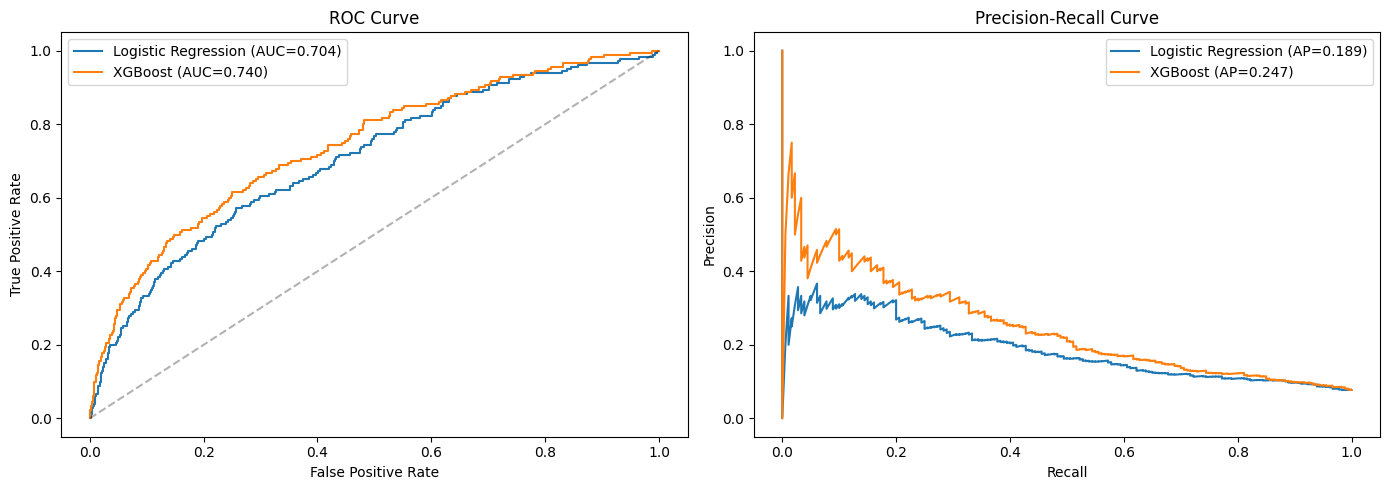

In [26]:
plt.figure(figsize=(14,5))

plt.subplot(1,2,1)
for name, probs in [("Logistic Regression", lr_probs), ("XGBoost", xgb_probs)]:
    fpr, tpr, _ = roc_curve(y_test, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, probs):.3f})")
plt.plot([0,1],[0,1],'k--', alpha=0.3)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curve'); plt.legend()

plt.subplot(1,2,2)
for name, probs in [("Logistic Regression", lr_probs), ("XGBoost", xgb_probs)]:
    precision, recall, _ = precision_recall_curve(y_test, probs)
    plt.plot(recall, precision, label=f"{name} (AP={average_precision_score(y_test, probs):.3f})")
plt.xlabel('Recall'); plt.ylabel('Precision')
plt.title('Precision-Recall Curve'); plt.legend()
plt.tight_layout(); plt.show()

In [27]:
def ks_table(y_true, y_probs, n_bins=10):
    df = pd.DataFrame({'y': y_true, 'prob': y_probs})
    df['decile'] = pd.qcut(df['prob'], n_bins, labels=False, duplicates='drop')
    grouped = df.groupby('decile').agg(
        total=('y', 'count'),
        defaults=('y', 'sum')
    ).sort_index(ascending=False)  # highest predicted risk first
    grouped['non_defaults'] = grouped['total'] - grouped['defaults']
    grouped['cum_default_pct'] = (grouped['defaults'].cumsum() / grouped['defaults'].sum()) * 100
    grouped['cum_nondefault_pct'] = (grouped['non_defaults'].cumsum() / grouped['non_defaults'].sum()) * 100
    grouped['KS'] = grouped['cum_default_pct'] - grouped['cum_nondefault_pct']
    return grouped

ks_table(y_test, xgb_probs)

,total,defaults,non_defaults,cum_default_pct,cum_nondefault_pct,KS
decile,,,,,,
9,233,65,168,36.111111,7.824872,28.286239
8,233,27,206,51.111111,17.419655,33.691456
7,232,20,212,62.222222,27.293898,34.928324
6,233,15,218,70.555556,37.447601,33.107954
5,232,14,218,78.333333,47.601304,30.732029
4,233,12,221,85.000000,57.894737,27.105263
3,233,8,225,89.444444,68.374476,21.069968
2,232,9,223,94.444444,78.761062,15.683382
1,233,7,226,98.333333,89.287378,9.045956


In [28]:
#Day 3
!pip install shap -q
import shap

In [29]:
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_xgb)

print(type(shap_values), shap_values.shape)
print("Expected value (base value):", explainer.expected_value)

<class 'numpy.ndarray'> (2327, 137)
Expected value (base value): 0.2268902


In [30]:
# Sanity check the additivity property directly on one row
row_idx = 0
print("Sum:", explainer.expected_value + shap_values[row_idx].sum())
print("Raw model margin output:", xgb_model.predict(X_test_xgb.iloc[[row_idx]], output_margin=True))

Sum: 0.43727028
Raw model margin output: [0.43727055]


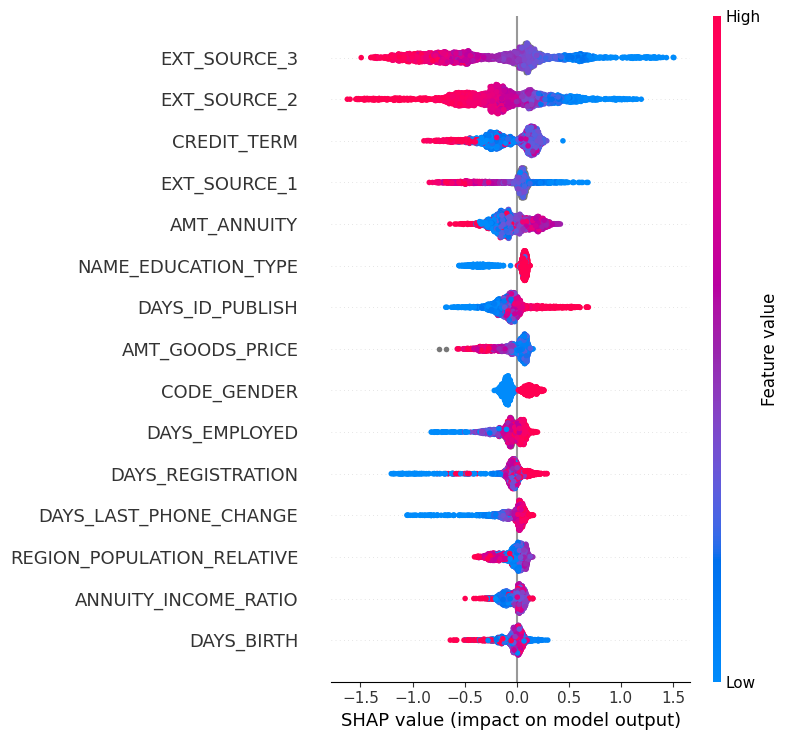

In [31]:
shap.summary_plot(shap_values, X_test_xgb, max_display=15)

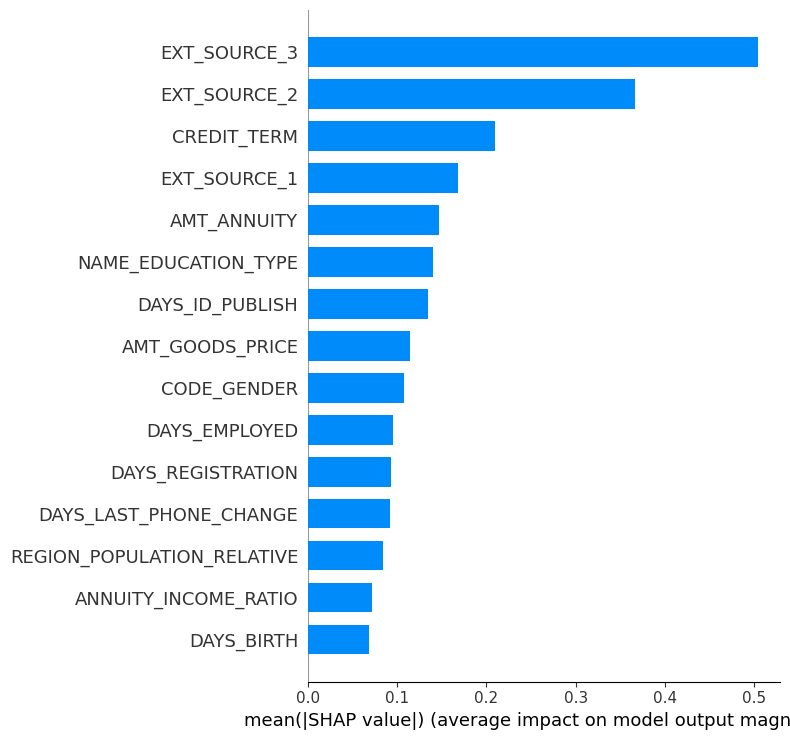

In [32]:
# Bar version — pure global ranking, easier to read at a glance for non-technical stakeholders
shap.summary_plot(shap_values, X_test_xgb, plot_type='bar', max_display=15)

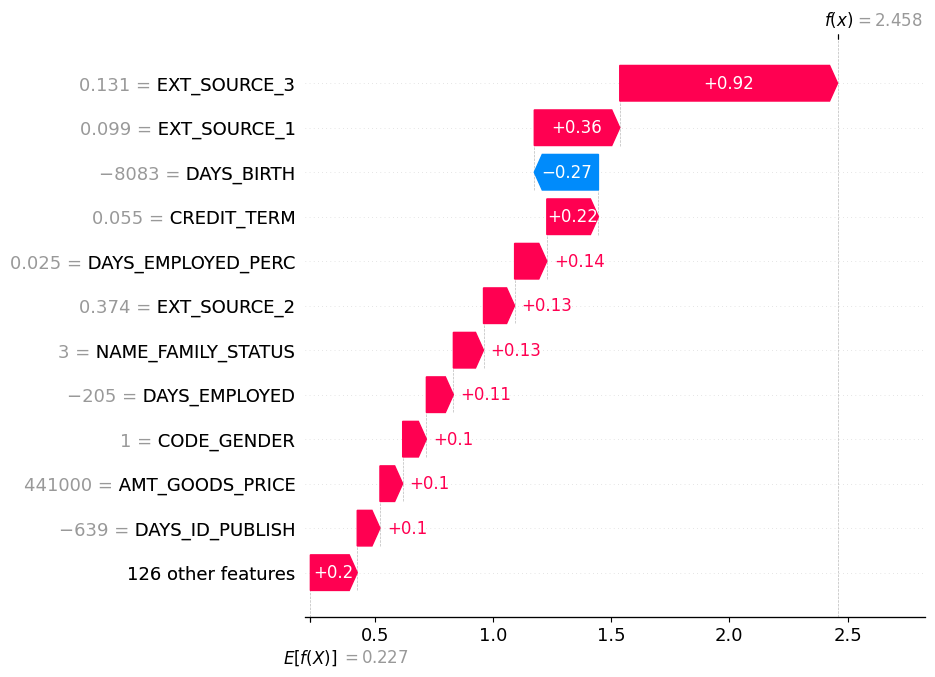

In [33]:
# Get predicted probabilities on the test set to pick interesting cases
test_results = X_test_xgb.copy()
test_results['y_true'] = y_test.values
test_results['pred_prob'] = xgb_probs

# Case 1: a correctly identified high-risk applicant (true default, high predicted prob)
high_risk_idx = test_results[(test_results['y_true']==1)].sort_values('pred_prob', ascending=False).index[0]
pos_loc = X_test_xgb.index.get_loc(high_risk_idx)

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[pos_loc],
        base_values=explainer.expected_value,
        data=X_test_xgb.iloc[pos_loc],
        feature_names=X_test_xgb.columns.tolist()
    ),
    max_display=12
)

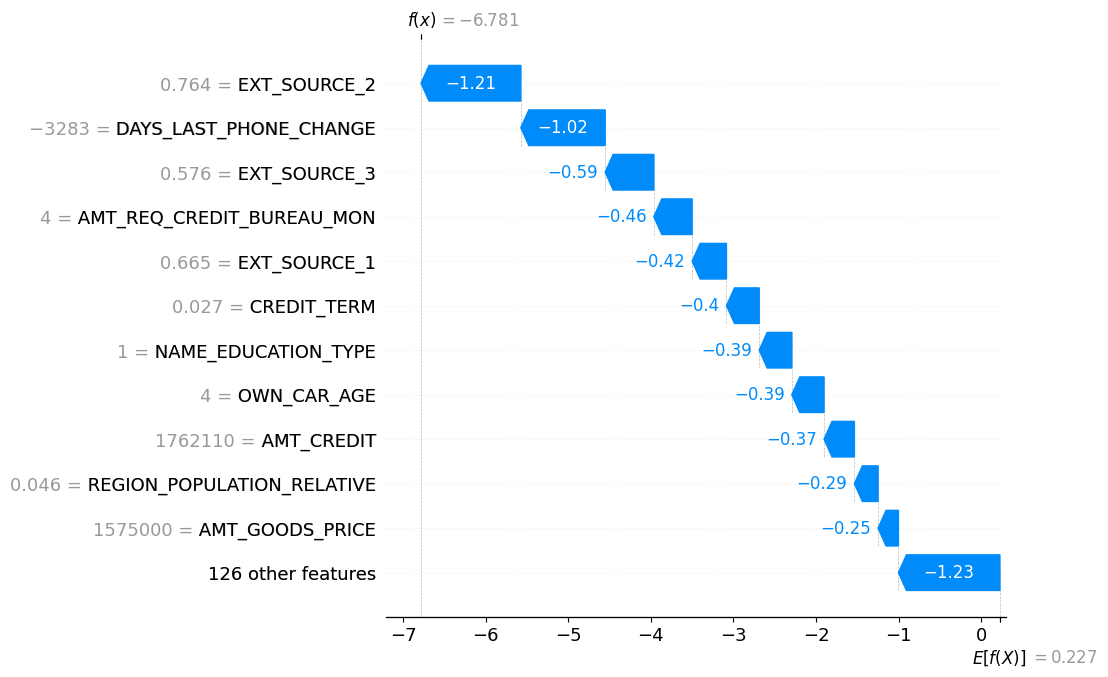

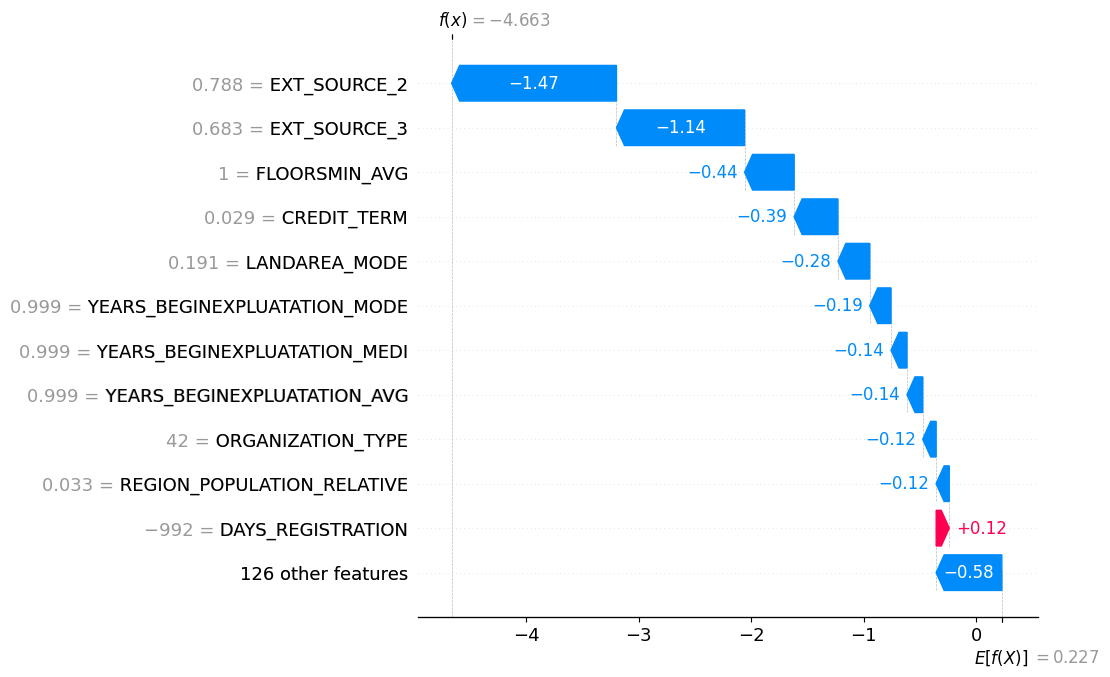

In [34]:
# Case 2: a correctly identified low-risk applicant
low_risk_idx = test_results[(test_results['y_true']==0)].sort_values('pred_prob', ascending=True).index[0]
neg_loc = X_test_xgb.index.get_loc(low_risk_idx)

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[neg_loc],
        base_values=explainer.expected_value,
        data=X_test_xgb.iloc[neg_loc],
        feature_names=X_test_xgb.columns.tolist()
    ),
    max_display=12
)

# Case 3 — the most valuable one for an interview: a mistake
# a defaulter the model scored as LOW risk (false negative) — where did the model get misled?
fn_idx = test_results[(test_results['y_true']==1)].sort_values('pred_prob', ascending=True).index[0]
fn_loc = X_test_xgb.index.get_loc(fn_idx)

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[fn_loc],
        base_values=explainer.expected_value,
        data=X_test_xgb.iloc[fn_loc],
        feature_names=X_test_xgb.columns.tolist()
    ),
    max_display=12
)

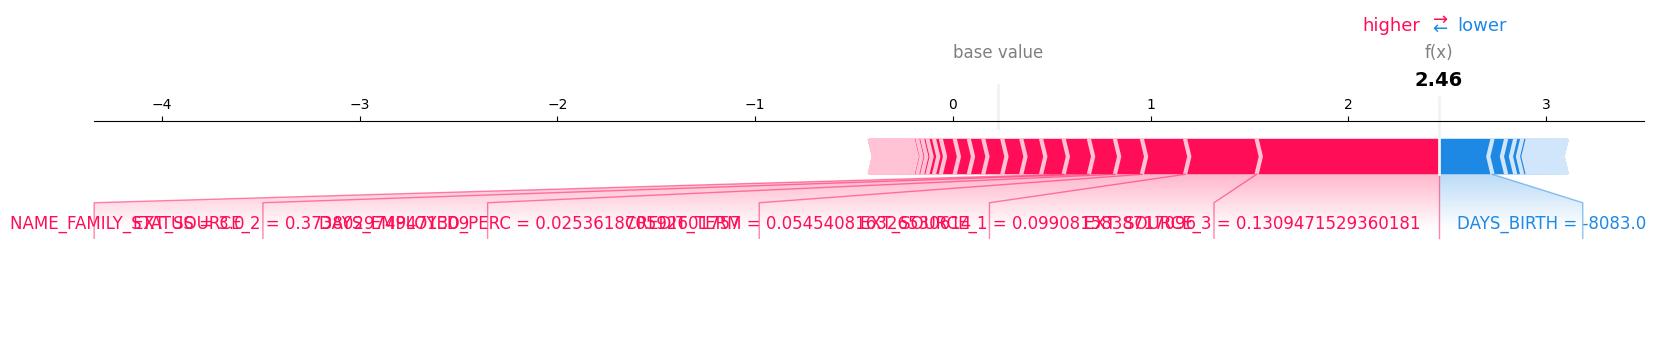

In [35]:
shap.initjs()
shap.force_plot(
    explainer.expected_value,
    shap_values[pos_loc],
    X_test_xgb.iloc[pos_loc],
    matplotlib=True
)

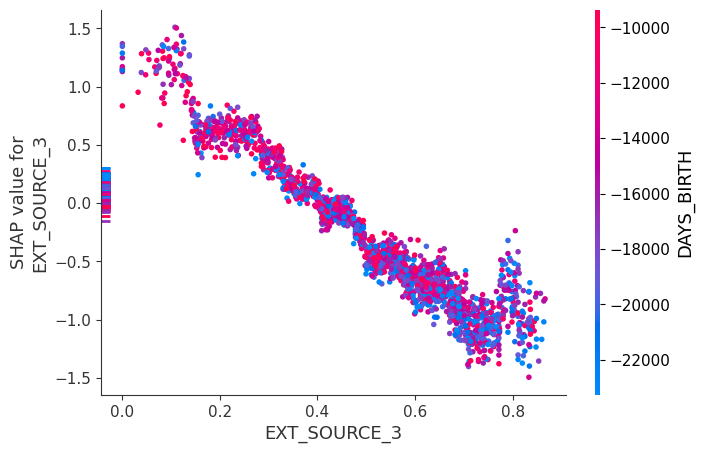

In [36]:
shap.dependence_plot(
    "EXT_SOURCE_3",
    shap_values,
    X_test_xgb,
    interaction_index="DAYS_BIRTH"
)

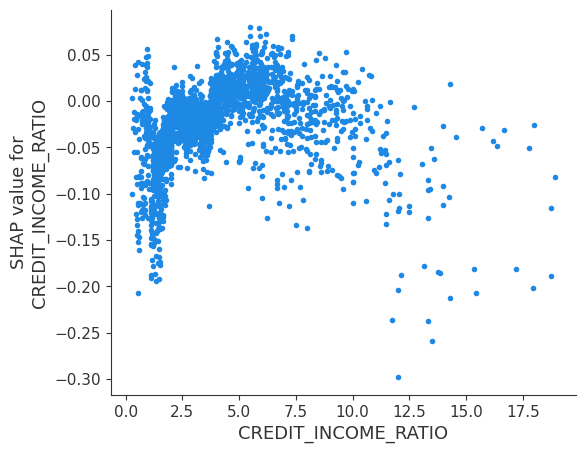

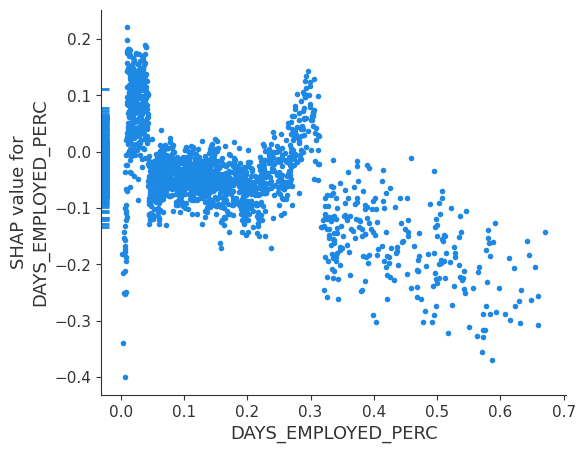

In [37]:
# A couple more, tied to your engineered features specifically —
# this directly validates whether your Day 1 feature engineering was worth it
shap.dependence_plot("CREDIT_INCOME_RATIO", shap_values, X_test_xgb, interaction_index=None)
shap.dependence_plot("DAYS_EMPLOYED_PERC", shap_values, X_test_xgb, interaction_index=None)

In [38]:
xgb_importance = pd.Series(xgb_model.feature_importances_, index=X_train_xgb.columns).sort_values(ascending=False)
shap_importance = pd.Series(np.abs(shap_values).mean(axis=0), index=X_test_xgb.columns).sort_values(ascending=False)

comparison = pd.DataFrame({
    'xgb_gain_rank': xgb_importance.rank(ascending=False),
    'shap_rank': shap_importance.rank(ascending=False)
}).sort_values('shap_rank').head(15)
print(comparison)

                            xgb_gain_rank  shap_rank
EXT_SOURCE_3                          2.0        1.0
EXT_SOURCE_2                          3.0        2.0
CREDIT_TERM                          14.0        3.0
EXT_SOURCE_1                          5.0        4.0
AMT_ANNUITY                          28.0        5.0
NAME_EDUCATION_TYPE                   4.0        6.0
DAYS_ID_PUBLISH                      25.0        7.0
AMT_GOODS_PRICE                      21.0        8.0
CODE_GENDER                          10.0        9.0
DAYS_EMPLOYED                        16.0       10.0
DAYS_REGISTRATION                    31.0       11.0
DAYS_LAST_PHONE_CHANGE               59.0       12.0
REGION_POPULATION_RELATIVE           40.0       13.0
ANNUITY_INCOME_RATIO                 30.0       14.0
DAYS_BIRTH                           55.0       15.0


In [43]:
#Day 4
import os
import joblib

# Create the folder if it doesn't exist
os.makedirs('model_artifacts', exist_ok=True)
# Save the model
joblib.dump(xgb_model, 'model_artifacts/xgb_model.pkl')


['model_artifacts/xgb_model.pkl']

In [44]:
# Save the trained model
joblib.dump(xgb_model, 'model_artifacts/xgb_model.pkl')

# Save the ordinal encoder — needed to transform raw categorical inputs identically at inference
joblib.dump(ordinal_encoder, 'model_artifacts/ordinal_encoder.pkl')


['model_artifacts/ordinal_encoder.pkl']

In [45]:
# Save the exact column order the model was trained on
feature_columns = X_train_xgb.columns.tolist()
with open('model_artifacts/feature_columns.json', 'w') as f:
    json.dump(feature_columns, f)

# Save which columns are categorical (need ordinal encoding) vs numeric (pass through)
with open('model_artifacts/cat_cols.json', 'w') as f:
    json.dump(cat_cols, f)

# Save a small reference sample for the SHAP explainer's background/typical-applicant context
# and for computing decile-based risk bands at inference time
X_train_xgb.sample(min(1000, len(X_train_xgb)), random_state=42).to_csv(
    'model_artifacts/background_sample.csv', index=False
)

In [46]:
# schemas.py
from pydantic import BaseModel, Field
from typing import Optional

class LoanApplication(BaseModel):
    AMT_INCOME_TOTAL: float = Field(..., gt=0, description="Total annual income")
    AMT_CREDIT: float = Field(..., gt=0, description="Loan amount requested")
    AMT_ANNUITY: float = Field(..., gt=0, description="Loan annuity (installment amount)")
    DAYS_BIRTH: int = Field(..., lt=0, description="Age in days, negative (Home Credit convention)")
    DAYS_EMPLOYED: Optional[float] = Field(None, description="Employment duration in days, negative")
    CODE_GENDER: str
    NAME_CONTRACT_TYPE: str
    NAME_INCOME_TYPE: str
    NAME_EDUCATION_TYPE: str
    ORGANIZATION_TYPE: str
    CNT_CHILDREN: int = Field(..., ge=0)
    # ... remaining fields from feature_columns.json follow the same pattern

    class Config:
        json_schema_extra = {
            "example": {
                "AMT_INCOME_TOTAL": 202500.0,
                "AMT_CREDIT": 406597.5,
                "AMT_ANNUITY": 24700.5,
                "DAYS_BIRTH": -9461,
                "DAYS_EMPLOYED": -637,
                "CODE_GENDER": "M",
                "NAME_CONTRACT_TYPE": "Cash loans",
                "NAME_INCOME_TYPE": "Working",
                "NAME_EDUCATION_TYPE": "Secondary / secondary special",
                "ORGANIZATION_TYPE": "Business Entity Type 3",
                "CNT_CHILDREN": 0
            }
        }

/tmp/ipykernel_1500/3307911589.py:5: PydanticDeprecatedSince20: Support for class-based `config` is deprecated, use ConfigDict instead. Deprecated in Pydantic V2.0 to be removed in V3.0. See Pydantic V2 Migration Guide at https://errors.pydantic.dev/2.13/migration/
  class LoanApplication(BaseModel):


In [48]:
from pydantic import BaseModel

class LoanApplication(BaseModel):
    AMT_INCOME_TOTAL: float
    AMT_CREDIT: float
    AMT_ANNUITY: float
    AMT_GOODS_PRICE: float
    DAYS_BIRTH: int
    DAYS_EMPLOYED: int
    CODE_GENDER: str
    NAME_INCOME_TYPE: str
    NAME_EDUCATION_TYPE: str
    NAME_FAMILY_STATUS: str
    OCCUPATION_TYPE: str

In [51]:
import os
print(os.listdir())

['.config', 'application_test.csv', 'bureau.csv', 'application_train.csv', '.ipynb_checkpoints', 'model_artifacts', 'sample_data']


In [52]:
!find /content -name "schemas.py"

In [53]:
%%writefile schemas.py
from pydantic import BaseModel

class LoanApplication(BaseModel):
    AMT_INCOME_TOTAL: float
    AMT_CREDIT: float
    AMT_ANNUITY: float
    AMT_GOODS_PRICE: float
    DAYS_BIRTH: int
    DAYS_EMPLOYED: int
    CODE_GENDER: str
    NAME_INCOME_TYPE: str
    NAME_EDUCATION_TYPE: str
    NAME_FAMILY_STATUS: str
    OCCUPATION_TYPE: str

Writing schemas.py


In [54]:
!ls

application_test.csv   bureau.csv	sample_data
application_train.csv  model_artifacts	schemas.py


In [55]:
!ls model_artifacts

background_sample.csv  feature_columns.json  xgb_model.pkl
cat_cols.json	       ordinal_encoder.pkl


In [56]:
# main.py
from fastapi import FastAPI, HTTPException
import pandas as pd
import numpy as np
import joblib
import json
import shap
from schemas import LoanApplication

app = FastAPI(
    title="Credit Risk Prediction API",
    description="XGBoost-based default risk scoring with SHAP explainability",
    version="1.0.0"
)

# Load artifacts once at startup, not per-request
xgb_model = joblib.load('model_artifacts/xgb_model.pkl')
ordinal_encoder = joblib.load('model_artifacts/ordinal_encoder.pkl')
feature_columns = json.load(open('model_artifacts/feature_columns.json'))
cat_cols = json.load(open('model_artifacts/cat_cols.json'))
background_sample = pd.read_csv('model_artifacts/background_sample.csv')

explainer = shap.TreeExplainer(xgb_model)

# Precompute decile cutoffs on the background sample for risk banding
background_scores = xgb_model.predict_proba(background_sample[feature_columns])[:, 1]
DECILE_CUTOFFS = np.percentile(background_scores, np.arange(10, 100, 10))


def band_risk(prob: float) -> str:
    decile = int(np.searchsorted(DECILE_CUTOFFS, prob)) + 1  # 1 = lowest risk decile
    if decile <= 3:
        return "Low Risk"
    elif decile <= 7:
        return "Medium Risk"
    else:
        return "High Risk"


@app.get("/health")
def health_check():
    return {"status": "ok", "model_version": app.version}


@app.post("/predict")
def predict(application: LoanApplication):
    try:
        input_df = pd.DataFrame([application.model_dump()])

        # Apply the SAME fitted encoder from training — not a new one
        input_df[cat_cols] = ordinal_encoder.transform(input_df[cat_cols])

        # Enforce exact training column order
        input_df = input_df.reindex(columns=feature_columns)

        prob = float(xgb_model.predict_proba(input_df)[:, 1][0])

        # SHAP explanation for this single prediction
        shap_vals = explainer.shap_values(input_df)[0]
        contributions = sorted(
            zip(feature_columns, shap_vals),
            key=lambda x: abs(x[1]),
            reverse=True
        )[:5]

        return {
            "default_probability": round(prob, 4),
            "risk_band": band_risk(prob),
            "base_rate": round(float(explainer.expected_value), 4),
            "top_contributing_factors": [
                {"feature": f, "shap_contribution": round(float(v), 4)}
                for f, v in contributions
            ]
        }

    except Exception as e:
        raise HTTPException(status_code=400, detail=str(e))

In [60]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful